## Problema - Conectando una protoboard con la menor cantidad de cable

**Instrucción:** completa esta plantilla con tu diseño y desarrollo.

In [ ]:
# @title Ingrese datos
nombre_estudiante = "Jonathan Audic Melendez Rodriguez" # @param {"type":"string"}
carnet = 1000113661 # @param {"type":"integer"}

## 1) Descripción del problema **[1 pts]**

Un equipo de electrónica ubicó siete componentes sobre una protoboard simplificada (30 columnas × 10 filas, A–J) y necesita conectarlos entre sí usando **la menor longitud total de cable posible**.

Se modela como un problema de grafos:

- **Vértices:** los componentes (F, L, S, P, B, R, M).
- **Aristas:** cada posible cable entre dos componentes (grafo completo, 7·6/2 = 21 aristas).
- **Peso:** longitud del cable, calculada con la distancia Manhattan col1 - col2 + fila1 - fila2 (A=1 … J=10).
- **Objetivo:** hallar el **Árbol de Expansión Mínima (MST)** con el **algoritmo de Kruskal** (implementado a mano, con Union-Find para evitar ciclos). Con 7 componentes el MST tiene exactamente 6 cables.

Además se visualiza la protoboard (inicial, todas las conexiones, MST) y se evalúa el efecto de **mover el Buzzer de H6 a J20**, recalculando todo automáticamente.

## 2) Requerimientos **[2 pts]**

**Funcionales**

- **RF1.** Representar gráficamente la protoboard (columnas 1–30, filas A–J) y ubicar los 7 componentes con su identificador.
- **RF2.** Convertir una posición tipo "C8" en coordenadas (columna, fila) con A=1 … J=10.
- **RF3.** Calcular automáticamente la distancia Manhattan entre cada pareja de componentes (sin escribir pesos a mano).
- **RF4.** Construir el grafo completo y mostrar todas las conexiones posibles con su peso.
- **RF5.** Implementar manualmente Kruskal: ordenar aristas, seleccionar las de menor peso y evitar ciclos (Union-Find).
- **RF6.** Obtener un MST con n − 1 aristas y calcular la longitud total de cable.
- **RF7.** Mostrar el resultado por consola (Cable 1, Cable 2, …, total) y gráficamente (solo aristas del MST).
- **RF8.** Permitir cambiar la posición de un componente (Buzzer: H6 → J20), recalcular grafo y MST, y comparar longitudes totales.

**No funcionales**

- **RNF1. Ejecutable:** corre de principio a fin en Google Colab / Jupyter usando solo la biblioteca estándar y matplotlib.
- **RNF2. Restricción de implementación:** no se usan librerías que calculen el MST (ni networkx, ni scipy).
- **RNF3. Eficiencia:** complejidad O(n² log n), adecuada para el tamaño del problema.
- **RNF4. Modularidad y legibilidad:** funciones pequeñas con una sola responsabilidad y nombres claros.
- **RNF5. Determinismo:** sin aleatoriedad en el flujo principal; mismos datos → mismo resultado (desempate estable por orden de aparición).
- **RNF6. Claridad visual:** gráficos con ejes rotulados, pesos visibles y colores consistentes por componente.
- **RNF7. Robustez:** valida posiciones fuera de la protoboard y grafos no conexos.

## 3) Historias de usuario **[2 pts]**

**HU1 – Visualizar la protoboard**
*Como* encargado del prototipo, *quiero* ver la protoboard con los componentes en sus posiciones, *para* verificar que la distribución es la correcta.
**Criterios de aceptación:**
- Se ven las columnas 1–30 y las filas A–J.
- Cada componente aparece con su identificador y su posición (ej. F en A3).
- El gráfico se genera desde el notebook.

**HU2 – Ver todas las conexiones posibles**
*Como* diseñador, *quiero* ver todos los cables posibles con su longitud, *para* entender las opciones antes de optimizar.
**Criterios de aceptación:**
- Se muestran las 21 conexiones posibles entre 7 componentes.
- Cada arista muestra su peso calculado automáticamente con la distancia Manhattan.
- El ejemplo F–L muestra 7.

**HU3 – Obtener el cableado mínimo**
*Como* ingeniero, *quiero* obtener el conjunto de cables que conecta todo con la menor longitud total, *para* ahorrar material.
**Criterios de aceptación:**
- El resultado tiene exactamente n − 1 = 6 cables, sin ciclos.
- Todos los componentes quedan conectados.
- Se imprime cada cable con su longitud y la longitud total.
- El resultado coincide con el óptimo verificado por fuerza bruta (sección 7).

**HU4 – Evaluar un cambio de distribución**
*Como* encargado, *quiero* mover un componente y ver el nuevo cableado, *para* saber si el cambio aumenta o reduce el cable necesario.
**Criterios de aceptación:**
- Al mover el Buzzer de H6 a J20 el grafo y el MST se recalculan automáticamente.
- Se muestran ambas longitudes totales (original y después del cambio).
- Se indica explícitamente si el total aumentó o disminuyó.

## 4) Diagramas de flujo **[5 pts]**

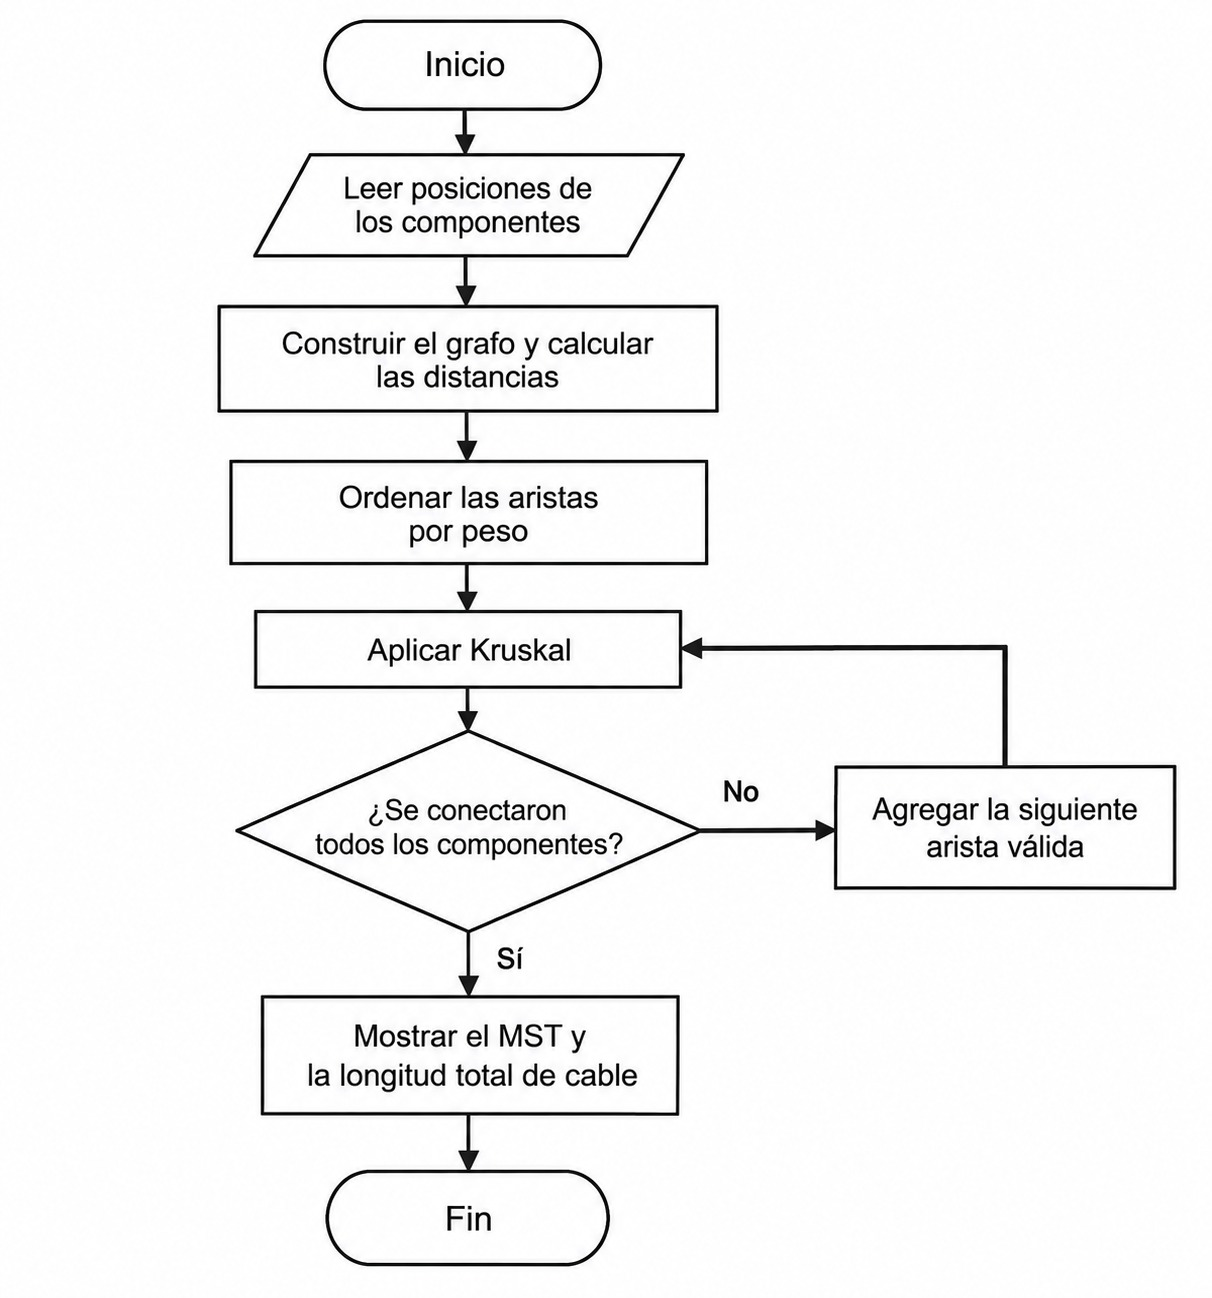

### 5) Análisis de complejidad **[15 pts]**
Análisis de complejidad
El algoritmo implementado corresponde a Kruskal, el cual construye el Árbol de Expansión Mínima (MST). Primero genera todas las conexiones posibles entre los componentes, luego las ordena por peso y finalmente selecciona las de menor costo evitando la formación de ciclos. La etapa que más tiempo consume es el ordenamiento de las aristas, por lo que la complejidad total del algoritmo es:
O(m log m)
donde m es el número de conexiones (aristas).

Mejor caso

En el mejor caso, el algoritmo debe ordenar todas las conexiones antes de construir el árbol, por lo que su complejidad es:
O(m log m)

Peor caso

En el peor caso también es necesario ordenar todas las aristas y recorrerlas para verificar que no se formen ciclos. Por ello la complejidad sigue siendo:
O(m log m)

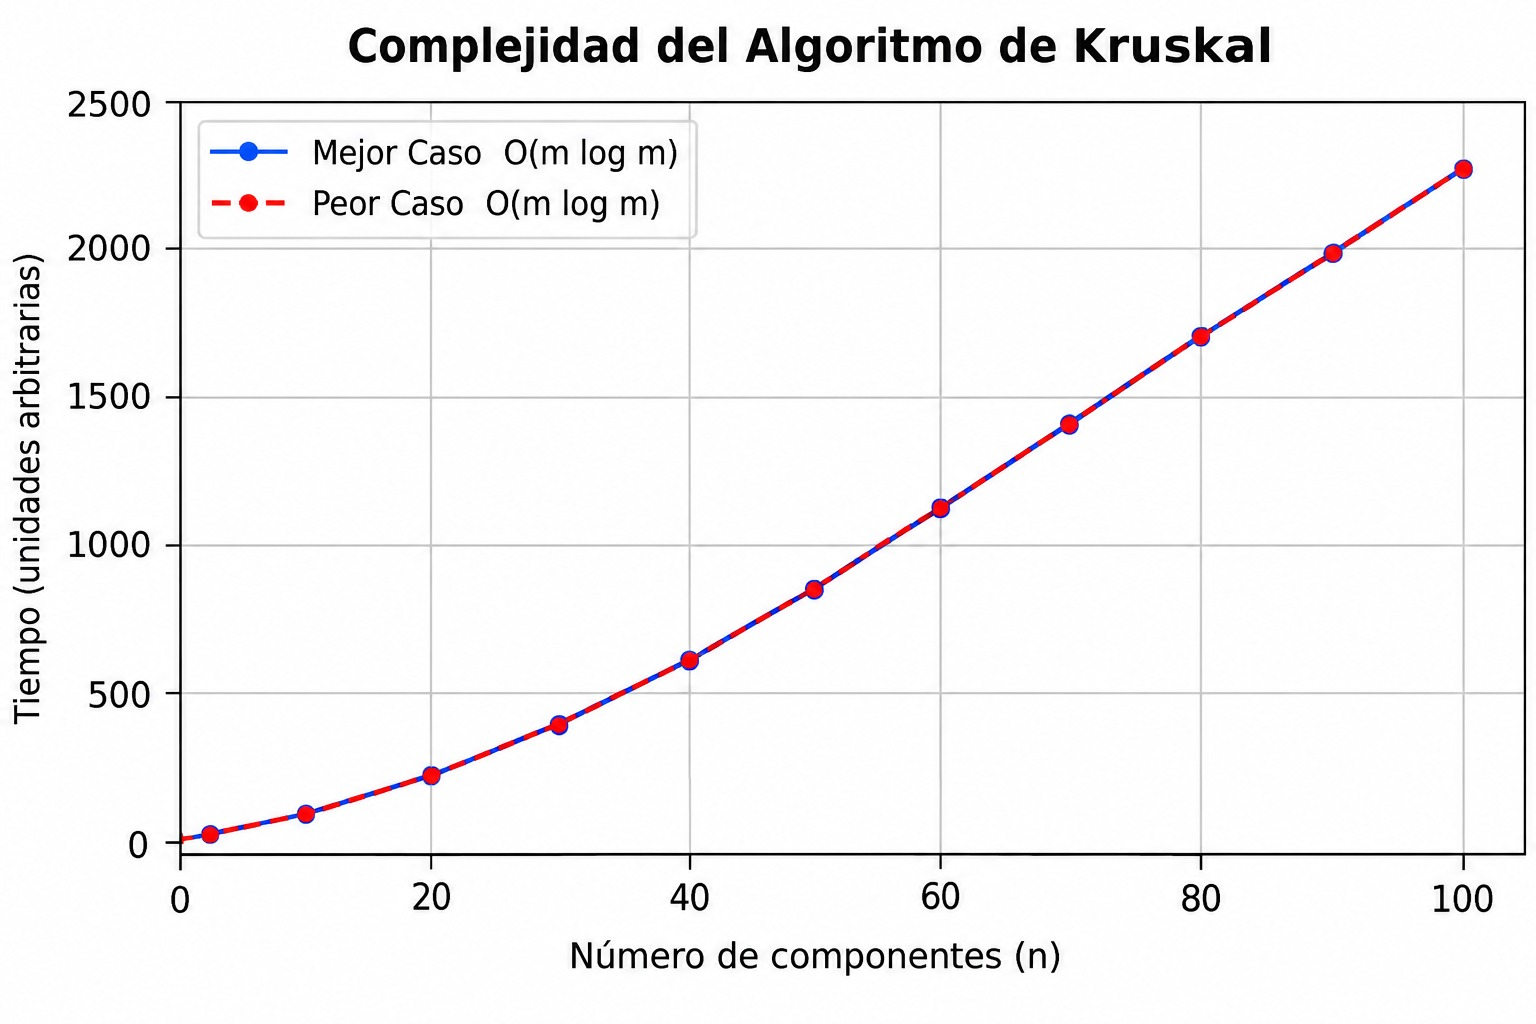

## 6) Código funcional **[15 pts]**



In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt


FILAS = {
    "A": 1, "B": 2, "C": 3, "D": 4, "E": 5,
    "F": 6, "G": 7, "H": 8, "I": 9, "J": 10
}

IDENTIFICADORES = {
    "Fuente de alimentación": "FA",
    "LED": "LC",
    "Sensor": "SB",
    "Pulsador": "PD",
    "Buzzer": "BH",
    "Potenciómetro": "RI",
    "Microcontrolador": "MG"
}


def obtener_fila_y_columna(posicion):
    fila_letra = posicion[0]
    columna_num = int(posicion[1:])
    fila_num = FILAS[fila_letra]
    return fila_num, columna_num


def calcular_distancia(pos1, pos2):
    fila1, col1 = obtener_fila_y_columna(pos1)
    fila2, col2 = obtener_fila_y_columna(pos2)

    diferencia_col = col1 - col2
    if diferencia_col < 0:
        diferencia_col = diferencia_col * -1

    diferencia_fila = fila1 - fila2
    if diferencia_fila < 0:
        diferencia_fila = diferencia_fila * -1

    return diferencia_col + diferencia_fila


def construir_grafo(componentes):
    vertices = []
    for comp in componentes:
        vertices.append(comp)

    aristas = []
    n = len(vertices)

    for i in range(n):
        for j in range(i + 1, n):
            u = vertices[i]
            v = vertices[j]
            peso = calcular_distancia(componentes[u], componentes[v])
            aristas.append([u, v, peso])

    return vertices, aristas



def buscar_padre(padres, vertice):
    if padres[vertice] == vertice:
        return vertice
    return buscar_padre(padres, padres[vertice])


def unir_conjuntos(padres, u, v):
    raiz_u = buscar_padre(padres, u)
    raiz_v = buscar_padre(padres, v)

    if raiz_u != raiz_v:
        padres[raiz_v] = raiz_u
        return True
    return False


def algoritmo_kruskal(vertices, aristas):
    aristas_ordenadas = sorted(aristas, key=lambda arista: arista[2])

    padres = {}
    for v in vertices:
        padres[v] = v

    mst = []
    longitud_total = 0

    for arista in aristas_ordenadas:
        u = arista[0]
        v = arista[1]
        peso = arista[2]

        if unir_conjuntos(padres, u, v) == True:
            mst.append(arista)
            longitud_total = longitud_total + peso

            if len(mst) == len(vertices) - 1:
                break

    return mst, longitud_total



def pos_a_coordenadas_grafica(posicion):
    fila_num, col_num = obtener_fila_y_columna(posicion)
    y = 11 - fila_num
    x = col_num
    return x, y


def mostrar_protoboard(componentes, aristas, titulo):
    fig, ax = plt.subplots(figsize=(13, 5))

    for fila in range(1, 11):
        for col in range(1, 31):
            ax.plot(col, 11 - fila, "o", color="#CCCCCC", markersize=4)

    if aristas != None:
        for u, v, peso in aristas:
            x1, y1 = pos_a_coordenadas_grafica(componentes[u])
            x2, y2 = pos_a_coordenadas_grafica(componentes[v])

            ax.plot([x1, x2], [y1, y2], "-", color="blue", linewidth=2, alpha=0.7)

            xm = (x1 + x2) / 2
            ym = (y1 + y2) / 2
            ax.text(
                xm,
                ym,
                str(peso),
                fontsize=9,
                color="black",
                fontweight="bold",
                bbox=dict(boxstyle="square,pad=0.2", facecolor="yellow", edgecolor="none")
            )

    for nombre in componentes:
        pos = componentes[nombre]
        x, y = pos_a_coordenadas_grafica(pos)
        id_comp = IDENTIFICADORES[nombre]

        ax.plot(x, y, "o", color="red", markersize=10, zorder=5)
        ax.text(
            x,
            y + 0.3,
            f"{nombre}\n({id_comp})",
            fontsize=8,
            ha="center",
            va="bottom",
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8)
        )

    ax.set_xticks(list(range(1, 31)))
    ax.set_yticks(list(range(1, 11)))
    ax.set_yticklabels(["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"][::-1])
    ax.set_xlim(0, 31)
    ax.set_ylim(0, 11)
    ax.set_title(titulo, fontweight="bold", fontsize=12)
    ax.set_xlabel("Columnas (1-30)")
    ax.set_ylabel("Filas (A-J)")
    ax.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()



componentes = {
    "Fuente de alimentación": "A3",
    "LED": "C8",
    "Sensor": "B16",
    "Pulsador": "D24",
    "Buzzer": "H6",
    "Potenciómetro": "I15",
    "Microcontrolador": "G25"
}

mostrar_protoboard(componentes, None, "Protoboard Inicial")

vertices, aristas = construir_grafo(componentes)

print("\n================ POSIBLES CONEXIONES ================")
for u, v, peso in aristas:
    id_u = IDENTIFICADORES[u]
    id_v = IDENTIFICADORES[v]
    print(f"{id_u} ({componentes[u]}) -------- {peso:2d} -------- {id_v} ({componentes[v]})")

mostrar_protoboard(componentes, aristas, "Todas las Posibles Conexiones")

# 4 y 5. Árbol de Expansión Mínima (Kruskal)
mst, longitud_original = algoritmo_kruskal(vertices, aristas)

print("\n========== RESULTADO ==========")
contador = 1
for u, v, peso in mst:
    id_u = IDENTIFICADORES[u]
    id_v = IDENTIFICADORES[v]
    print(f"Cable {contador}: {id_u} - {id_v} = {peso}")
    contador = contador + 1

print(f"Longitud total de cable: {longitud_original} unidades")

mostrar_protoboard(
    componentes,
    mst,
    f"Árbol de Expansión Mínima (Total: {longitud_original} unidades)"
)

componentes_mod = {}
for key in componentes:
    componentes_mod[key] = componentes[key]

componentes_mod["Buzzer"] = "J20"

vertices_mod, aristas_mod = construir_grafo(componentes_mod)
mst_mod, longitud_mod = algoritmo_kruskal(vertices_mod, aristas_mod)

print(f"\nMST original Longitud total: {longitud_original}")
print(f"MST después del cambio Longitud total: {longitud_mod}")

print("\n========== RESULTADO NUEVA POSICIÓN ==========")
contador = 1
for u, v, peso in mst_mod:
    id_u = IDENTIFICADORES[u]
    id_v = IDENTIFICADORES[v]
    print(f"Cable {contador}: {id_u} - {id_v} = {peso}")
    contador = contador + 1

mostrar_protoboard(
    componentes_mod,
    mst_mod,
    f"MST Modificado (Total: {longitud_mod} unidades)"
)

if longitud_mod > longitud_original:
    diferencia = longitud_mod - longitud_original
    print(f"\nRespuesta: La cantidad total de cable AUMENTÓ en {diferencia} unidades.")
elif longitud_mod < longitud_original:
    diferencia = longitud_original - longitud_mod
    print(f"\nRespuesta: La cantidad total de cable DISMINUYÓ en {diferencia} unidades.")
else:
    print("\nRespuesta: La cantidad total de cable MANTUVO la misma longitud.")

## 7) Tests aplicados **[15 pts]**


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt


FILAS = {
    "A": 1, "B": 2, "C": 3, "D": 4, "E": 5,
    "F": 6, "G": 7, "H": 8, "I": 9, "J": 10
}

IDENTIFICADORES = {
    "Fuente de alimentación": "FA",
    "LED": "LC",
    "Sensor": "SB",
    "Pulsador": "PD",
    "Buzzer": "BH",
    "Potenciómetro": "RI",
    "Microcontrolador": "MG"
}


def obtener_fila_y_columna(posicion):
    fila_letra = posicion[0]
    columna_num = int(posicion[1:])
    fila_num = FILAS[fila_letra]
    return fila_num, columna_num


def calcular_distancia(pos1, pos2):
    fila1, col1 = obtener_fila_y_columna(pos1)
    fila2, col2 = obtener_fila_y_columna(pos2)

    diferencia_col = col1 - col2
    if diferencia_col < 0:
        diferencia_col = diferencia_col * -1

    diferencia_fila = fila1 - fila2
    if diferencia_fila < 0:
        diferencia_fila = diferencia_fila * -1

    return diferencia_col + diferencia_fila


def construir_grafo(componentes):
    vertices = []
    for comp in componentes:
        vertices.append(comp)

    aristas = []
    n = len(vertices)

    for i in range(n):
        for j in range(i + 1, n):
            u = vertices[i]
            v = vertices[j]
            peso = calcular_distancia(componentes[u], componentes[v])
            aristas.append([u, v, peso])

    return vertices, aristas



def buscar_padre(padres, vertice):
    if padres[vertice] == vertice:
        return vertice
    return buscar_padre(padres, padres[vertice])


def unir_conjuntos(padres, u, v):
    raiz_u = buscar_padre(padres, u)
    raiz_v = buscar_padre(padres, v)

    if raiz_u != raiz_v:
        padres[raiz_v] = raiz_u
        return True
    return False


def algoritmo_kruskal(vertices, aristas):
    aristas_ordenadas = sorted(aristas, key=lambda arista: arista[2])

    padres = {}
    for v in vertices:
        padres[v] = v

    mst = []
    longitud_total = 0

    for arista in aristas_ordenadas:
        u = arista[0]
        v = arista[1]
        peso = arista[2]

        if unir_conjuntos(padres, u, v) == True:
            mst.append(arista)
            longitud_total = longitud_total + peso

            if len(mst) == len(vertices) - 1:
                break

    return mst, longitud_total



def pos_a_coordenadas_grafica(posicion):
    fila_num, col_num = obtener_fila_y_columna(posicion)
    y = 11 - fila_num
    x = col_num
    return x, y


def mostrar_protoboard(componentes, aristas, titulo):
    fig, ax = plt.subplots(figsize=(13, 5))

    for fila in range(1, 11):
        for col in range(1, 31):
            ax.plot(col, 11 - fila, "o", color="#CCCCCC", markersize=4)

    if aristas != None:
        for u, v, peso in aristas:
            x1, y1 = pos_a_coordenadas_grafica(componentes[u])
            x2, y2 = pos_a_coordenadas_grafica(componentes[v])

            ax.plot([x1, x2], [y1, y2], "-", color="blue", linewidth=2, alpha=0.7)

            xm = (x1 + x2) / 2
            ym = (y1 + y2) / 2
            ax.text(
                xm,
                ym,
                str(peso),
                fontsize=9,
                color="black",
                fontweight="bold",
                bbox=dict(boxstyle="square,pad=0.2", facecolor="yellow", edgecolor="none")
            )

    for nombre in componentes:
        pos = componentes[nombre]
        x, y = pos_a_coordenadas_grafica(pos)
        id_comp = IDENTIFICADORES[nombre]

        ax.plot(x, y, "o", color="red", markersize=10, zorder=5)
        ax.text(
            x,
            y + 0.3,
            f"{nombre}\n({id_comp})",
            fontsize=8,
            ha="center",
            va="bottom",
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8)
        )

    ax.set_xticks(list(range(1, 31)))
    ax.set_yticks(list(range(1, 11)))
    ax.set_yticklabels(["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"][::-1])
    ax.set_xlim(0, 31)
    ax.set_ylim(0, 11)
    ax.set_title(titulo, fontweight="bold", fontsize=12)
    ax.set_xlabel("Columnas (1-30)")
    ax.set_ylabel("Filas (A-J)")
    ax.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()



componentes = {
    "Fuente de alimentación": "A3",
    "LED": "C8",
    "Sensor": "B16",
    "Pulsador": "D24",
    "Buzzer": "H6",
    "Potenciómetro": "I15",
    "Microcontrolador": "G25"
}

mostrar_protoboard(componentes, None, "Protoboard Inicial")

vertices, aristas = construir_grafo(componentes)

print("\n================ POSIBLES CONEXIONES ================")
for u, v, peso in aristas:
    id_u = IDENTIFICADORES[u]
    id_v = IDENTIFICADORES[v]
    print(f"{id_u} ({componentes[u]}) -------- {peso:2d} -------- {id_v} ({componentes[v]})")

mostrar_protoboard(componentes, aristas, "Todas las Posibles Conexiones")

# 4 y 5. Árbol de Expansión Mínima (Kruskal)
mst, longitud_original = algoritmo_kruskal(vertices, aristas)

print("\n========== RESULTADO ==========")
contador = 1
for u, v, peso in mst:
    id_u = IDENTIFICADORES[u]
    id_v = IDENTIFICADORES[v]
    print(f"Cable {contador}: {id_u} - {id_v} = {peso}")
    contador = contador + 1

print(f"Longitud total de cable: {longitud_original} unidades")

mostrar_protoboard(
    componentes,
    mst,
    f"Árbol de Expansión Mínima (Total: {longitud_original} unidades)"
)

componentes_mod = {}
for key in componentes:
    componentes_mod[key] = componentes[key]

componentes_mod["Buzzer"] = "J20"

vertices_mod, aristas_mod = construir_grafo(componentes_mod)
mst_mod, longitud_mod = algoritmo_kruskal(vertices_mod, aristas_mod)

print(f"\nMST original Longitud total: {longitud_original}")
print(f"MST después del cambio Longitud total: {longitud_mod}")

print("\n========== RESULTADO NUEVA POSICIÓN ==========")
contador = 1
for u, v, peso in mst_mod:
    id_u = IDENTIFICADORES[u]
    id_v = IDENTIFICADORES[v]
    print(f"Cable {contador}: {id_u} - {id_v} = {peso}")
    contador = contador + 1

mostrar_protoboard(
    componentes_mod,
    mst_mod,
    f"MST Modificado (Total: {longitud_mod} unidades)"
)

if longitud_mod > longitud_original:
    diferencia = longitud_mod - longitud_original
    print(f"\nRespuesta: La cantidad total de cable AUMENTÓ en {diferencia} unidades.")
elif longitud_mod < longitud_original:
    diferencia = longitud_original - longitud_mod
    print(f"\nRespuesta: La cantidad total de cable DISMINUYÓ en {diferencia} unidades.")
else:
    print("\nRespuesta: La cantidad total de cable MANTUVO la misma longitud.")